In [1]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import sys
sys.path.append('../../../python_modules/')
# plt.rcdefaults() 
plt.rcParams['figure.dpi'] = 200
plt.rcParams['pdf.fonttype'] = '42'

from generic_plotting_functions import *

from domino.models.domino_models import DominoSingleOutput


import pandas as pd
import os
import numpy as np

from load_modisco import *
import json
from domino.utils.tools import seq_from_df

import pysam

import coolbox
from coolbox.api import *

import torch

In [2]:
boundaries_df = pd.read_csv('finalized_nc14_cluster_metadata.csv', index_col=0)
attributions_df = pd.read_csv('finalized_nc14_cluster_attributions.csv', index_col=0)

boundaries_df['idx'] = boundaries_df.index
sf1 = boundaries_df.query('chrom == "chr3R" and start > 6853601 and end < 6873800').iloc[0]
sf2 = boundaries_df.query('chrom == "chr3R" and start > 6853601 and end < 6873800').iloc[1]

In [4]:
boundaries_df.query('chrom == "chr3R" and start > 6853601 and end < 6873800')

,chrom,start,end,ins_score_1,copy_index_1,ins_score_2,copy_index_2,boundary,demeaned_ins_score_1,demeaned_ins_score_2,...,bucket,cp190,prop_nan,has_stripe_at_bound,CP190,cluster,num_strong_motif_classes,num_weak_motif_classes,contains_tss,idx
2897,chr3R,6854401,6854600,-0.516602,418828,-0.548114,418828,1,-0.720554,-0.635097,...,"(1.4, 1.5]",57.064455,0.009925,False,57.064455,16,2,1,False,2897
2899,chr3R,6870801,6871000,-0.593864,418910,-1.131912,418910,1,-0.881796,-1.248641,...,"(2.1, 2.2]",42.185806,0.009925,False,42.185806,21,2,1,False,2899


In [3]:
print('SF1', sf1.demeaned_ins_score_1)
print('SF2', sf2.demeaned_ins_score_1)

SF1 -0.7205535826228914
SF2 -0.8817958570129815


[ERROR:tab.py:300 -                query()] Reference sequence chr3R not found in index header.


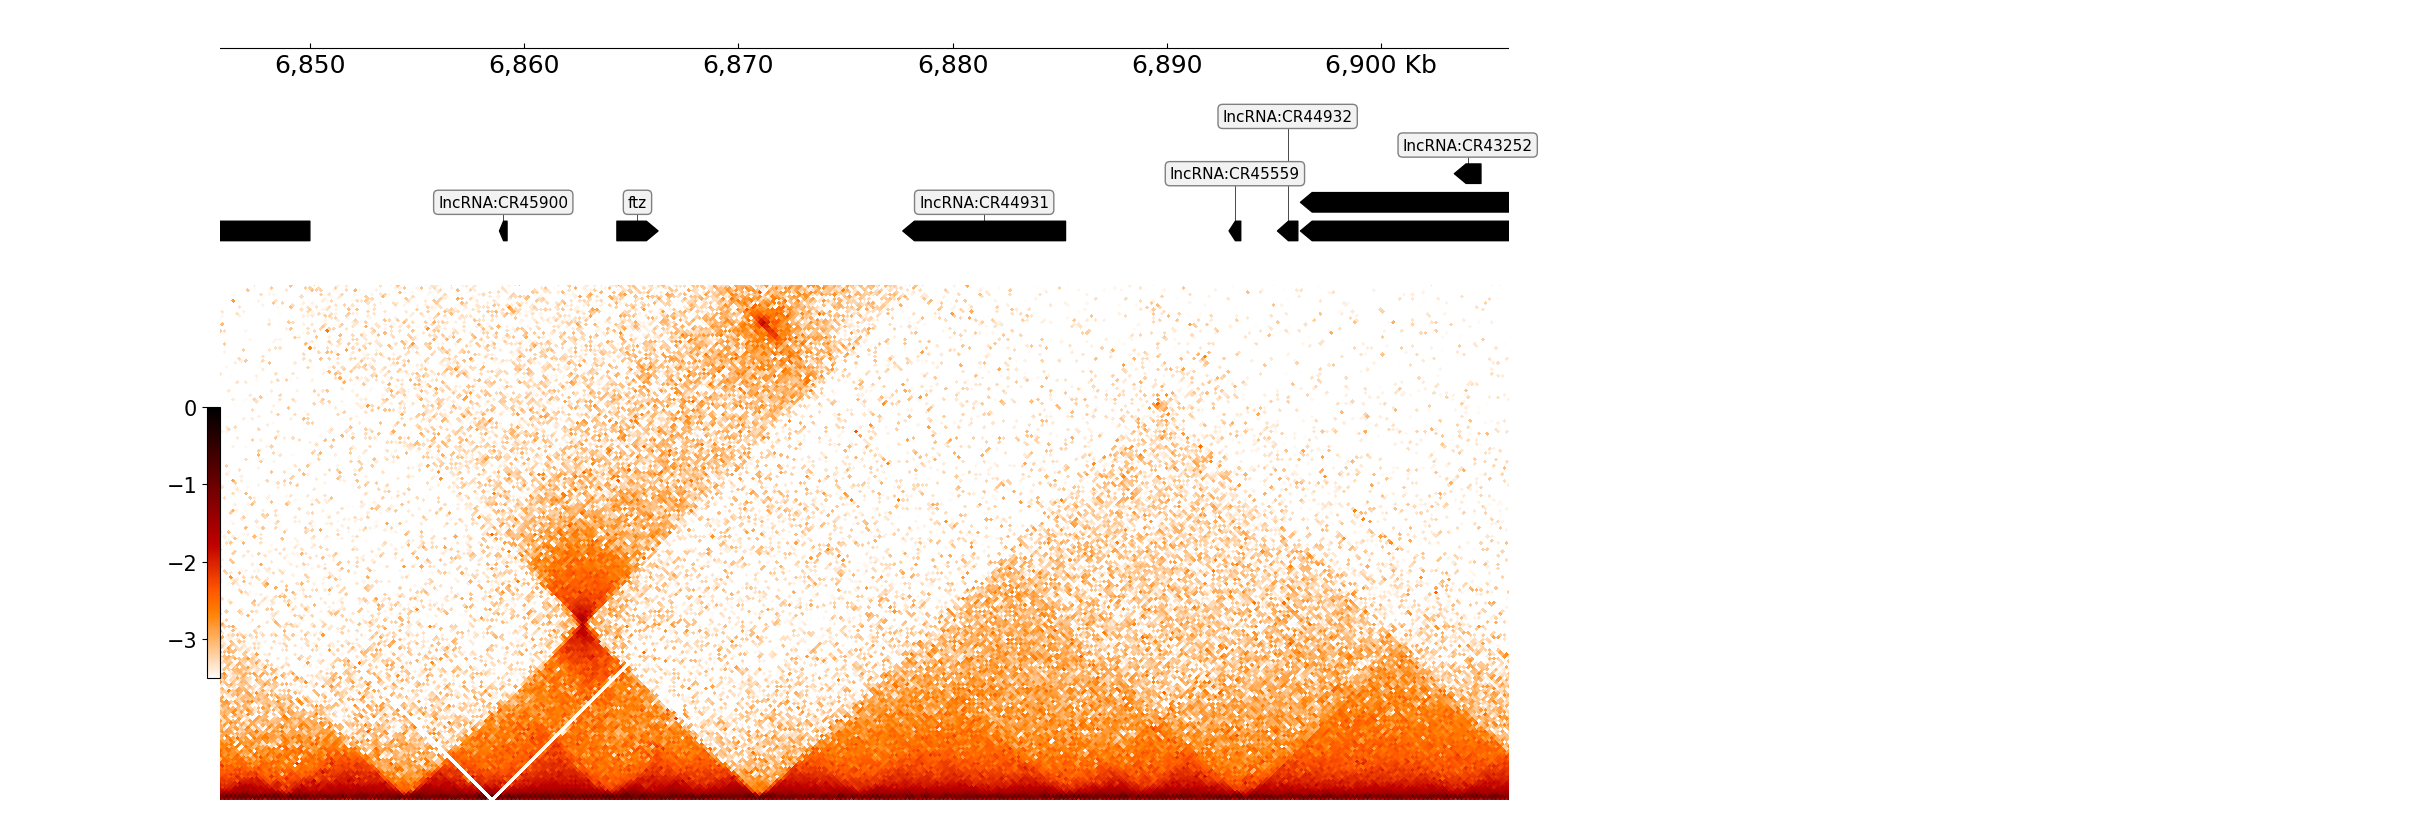

chr3R:6845801-6906000


In [8]:
plt.rcParams.update(plt.rcParamsDefault)
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['font.size'] = 18

MCOOL_DATA_DIR='/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/mcools/'
RESOLUTION=200
NUM_MERGED=11

chrom, start, end = "chr3R", 6870801, 6871000

# loffset, roffset = 50000, 35000
loffset, roffset = 25000, 35000

HIC_KWARGS = dict(
    style='window', 
    resolution=200, 
    depth_ratio=0.8, 
    cmap='gist_heat_r', 
    norm='no', 
    transform='log10', 
    max_value=0, 
    min_value=-3.5, 
    grid=False,
)

frame = [
    coolbox.api.XAxis(fontsize=18, show_chrom=True),
    coolbox.api.GTF('/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/annotations/Drosophila_melanogaster.BDGP6.54.115.gtf',
                                                        row_filter="type == 'gene'", color="#000000"), 
    TrackHeight(4),
    coolbox.api.Spacer(1), 
    # Map
    coolbox.api.HiCMat(f"{MCOOL_DATA_DIR}/new_nc14_embryo_merged_all_11.mcool", **HIC_KWARGS),
    coolbox.api.Spacer(), coolbox.api.TrackHeight(0.25),

]
from functools import reduce

frame = reduce(lambda x, y: x + y, frame)
fig = frame.plot(f"{chrom}:{start-loffset}-{end + roffset}")
fig.set(facecolor="white")
# fig.savefig("plots/scr_locus.pdf", format="pdf")
display(fig)

print(f"{chrom}:{start-loffset}-{end + roffset}")

## SF1 and SF2

In [5]:
X_attr = np.load('/scratch/gpfs/PRITYKIN/brendan/domino/output/06_12_2026_final_nc14_no_mig/DominoSingleOutput_10_16_2_1_200_32_False_False_42_0.001_plateau_5_1_512_5_256_5_4_64_gelu/numpy_arrs/windowed_attributions.bound_score_gt_1.npy')
X = torch.tensor(np.load('/scratch/gpfs/PRITYKIN/brendan/domino/output/06_12_2026_final_nc14_no_mig/DominoSingleOutput_10_16_2_1_200_32_False_False_42_0.001_plateau_5_1_512_5_256_5_4_64_gelu/numpy_arrs/windowed_ohe.bound_score_gt_1.npy'))

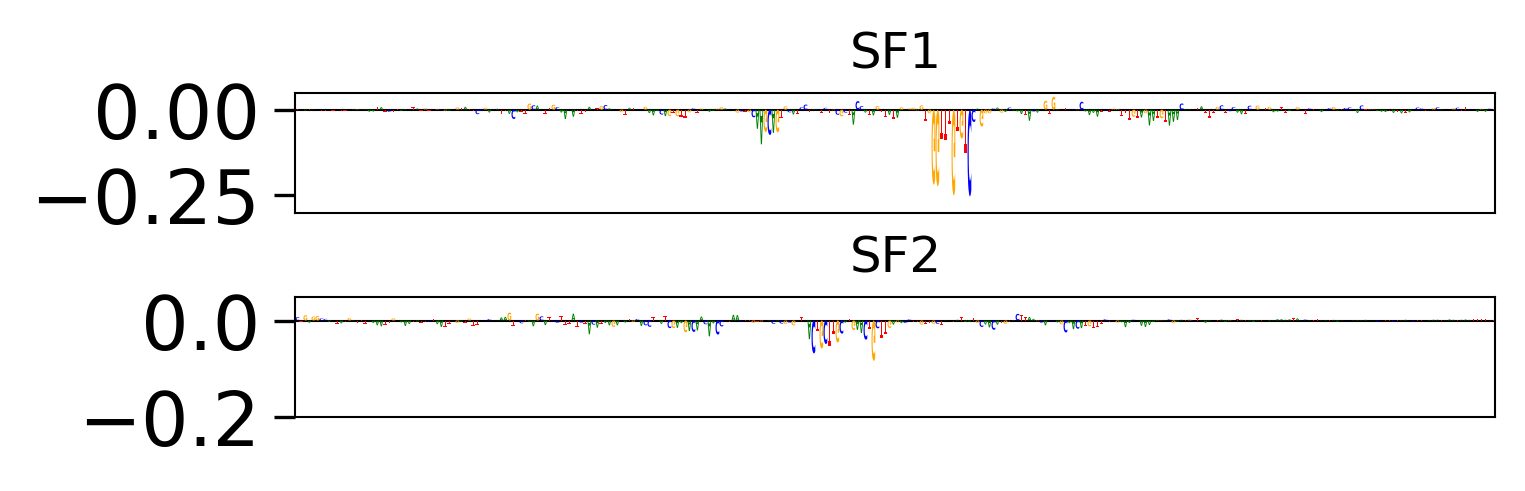

In [9]:
%matplotlib inline
from tangermeme.plot import plot_logo


sf1_attr = X_attr[sf1.idx * 2][:, 100:400]
sf2_attr = X_attr[sf2.idx * 2][:, 300:]

fig, axs = init_subplots_exact(2,2,dpi=300, y_ratios=[0.1] * 3, x_ratios=[1], yspace=1.7)
ax = axs[0]
plt.sca(axs[0])
logo = plot_logo(sf1_attr, ax=ax)
ax.grid(False)
ax.set_xticks([])
ax.set_xticklabels([])
ax.tick_params(axis='both', which='both', length=5)  # Adjust tick length if needed

for spine in ax.spines.values():
    spine.set_visible(True)  
    spine.set_linewidth(0.5)  
    spine.set_edgecolor("black")  
plt.ylim([-0.3, 0.05])
plt.title('SF1', fontsize=12)


ax = axs[1]
plt.sca(axs[1])
logo = plot_logo(sf2_attr, ax=ax)
ax.grid(False)
ax.set_xticks([])
ax.set_xticklabels([])
ax.tick_params(axis='both', which='both', length=5)  # Adjust tick length if needed

for spine in ax.spines.values():
    spine.set_visible(True)  
    spine.set_linewidth(0.5)  
    spine.set_edgecolor("black")  

plt.ylim([-0.2, 0.05])
plt.title('SF2', fontsize=12)


plt.show()

## Scr TE

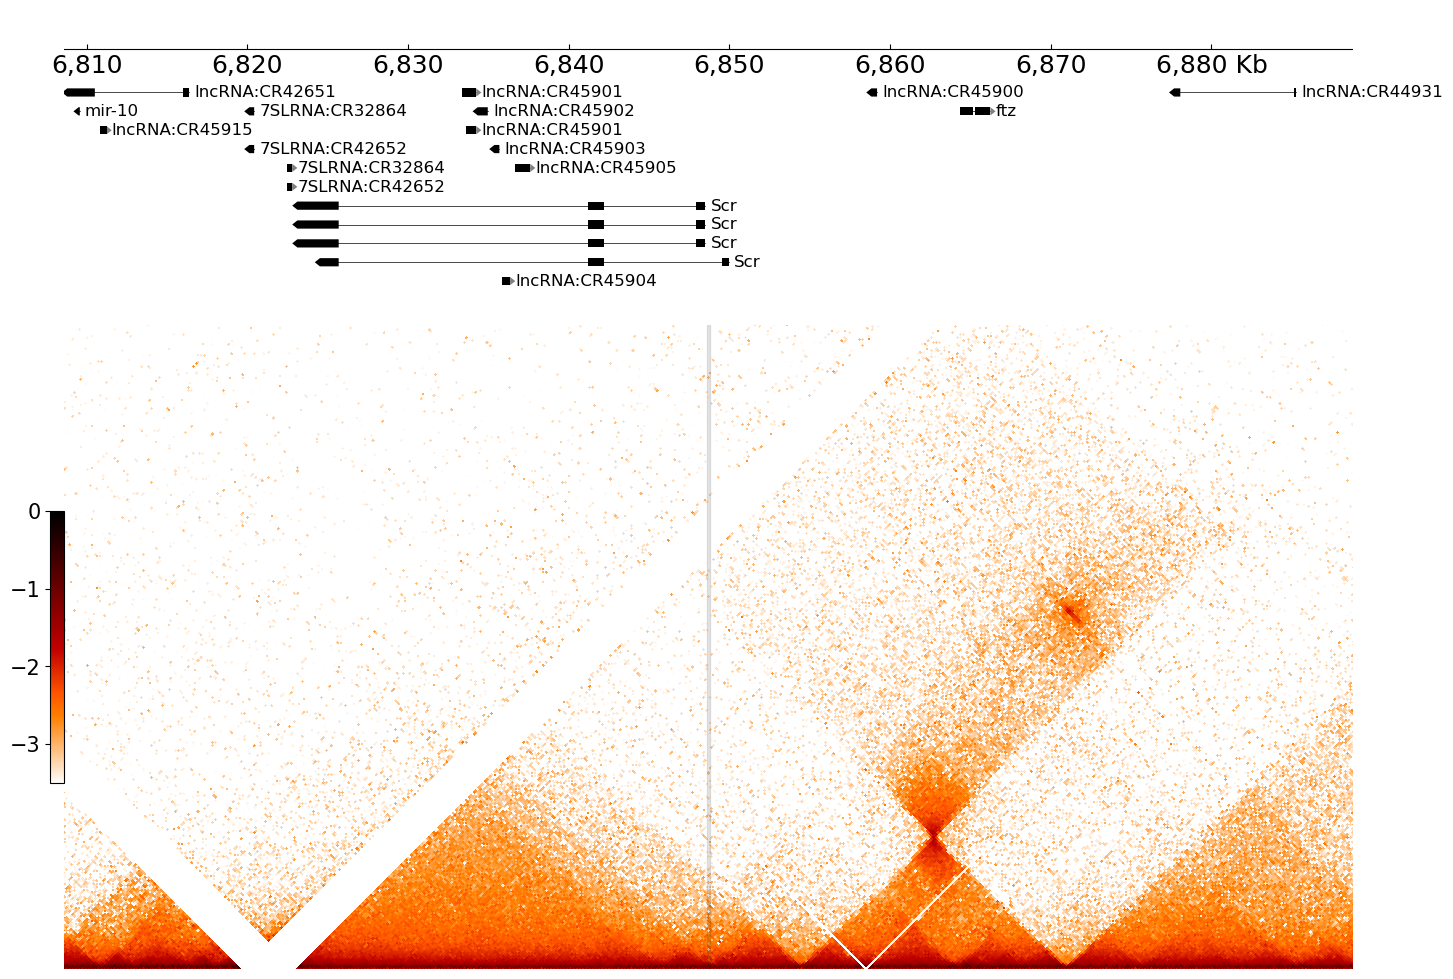

In [11]:
%matplotlib inline
# boundary = sf1.chrom, sf1.start, sf1.end
boundary = "chr3R", 6848601, 6848800
chrom, start, end = boundary

plt.rcParams.update(plt.rcParamsDefault)
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['font.size'] = 18

MCOOL_DATA_DIR='/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/mcools/'
ANNOT_DATA_DIR='/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/annotations/'
RESOLUTION=200
NUM_MERGED=11

HIC_KWARGS = dict(
    style='window', 
    resolution=200, 
    depth_ratio=1, 
    cmap='gist_heat_r', 
    norm='no', 
    transform='log10', 
    max_value=0, 
    min_value=-3.5, 
    grid=False,
)

frame = [
    coolbox.api.XAxis(fontsize=18, show_chrom=True),
    coolbox.api.BED(f"{ANNOT_DATA_DIR}/dm6.refGene.bed", gene_style='flybase', color='k', border_color=None),
    coolbox.api.Spacer(),
    coolbox.api.HiCMat(f"{MCOOL_DATA_DIR}/new_nc14_embryo_merged_all_11.mcool", **HIC_KWARGS),
    coolbox.core.coverage.HighLights(boundary, color='black', alpha=0.1),
    
]
from functools import reduce

frame = reduce(lambda x, y: x + y, frame)
fig = frame.plot(f"{chrom}:{start-40_000}-{end + 40_000}")
fig.set(facecolor="white")
# fig.savefig("/scratch/gpfs/PRITYKIN/brendan/domino/figures/strong_pred_locus.pdf", format="pdf")
display(fig)

In [12]:
model_dir = '/scratch/gpfs/PRITYKIN/brendan/domino/output/06_12_2026_final_nc14_no_mig/DominoSingleOutput_10_16_2_1_200_32_False_False_42_0.001_plateau_5_1_512_5_256_5_4_64_gelu/'
# model_dir = '/scratch/gpfs/PRITYKIN/brendan/domino/output/01_17_2025/DominoSingleOutput_10_8_2_1_200_32_False_False_42_0.001_plateau_4_1_512_5_256_5_4_64'

DNA_context_bin_width=16
DNA_context_length = 200*DNA_context_bin_width


TRAIN_df = pd.read_csv(os.path.join(model_dir, 'TRAIN_df.csv'))
VAL_df = pd.read_csv(os.path.join(model_dir, 'VAL_df.csv'))
TEST_df = pd.read_csv(os.path.join(model_dir, 'TEST_df.csv'))

def add_residual_column(df):
    df['residual'] = df['demeaned_ins_score_1'] - df['pred']
    df['abs_residual'] = (df['demeaned_ins_score_1'] - df['pred']).abs()
    
for df in [TRAIN_df, VAL_df, TEST_df]:
    df = add_residual_column(df)
    
genome_path = '/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/annotations/dm6.fa'
genome_fasta = pysam.FastaFile(genome_path)

print(os.listdir(model_dir + '/checkpoint')[0])

model_checkpoint_path = f"{model_dir}/checkpoint/{os.listdir(model_dir + '/checkpoint')[0]}"
model = DominoSingleOutput.load_from_checkpoint(model_checkpoint_path, activation='gelu')
model.eval()

epoch=9-step=83001.ckpt
fc dim 206
extra dim 6


DominoSingleOutput(
  (activation): GELU(approximate='none')
  (conv0): Sequential(
    (0): Conv1d(4, 512, kernel_size=(5,), stride=(1,), padding=same)
    (1): GELU(approximate='none')
    (2): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  )
  (convlayers): ModuleList(
    (0): Sequential(
      (0): Conv1d(512, 256, kernel_size=(5,), stride=(1,), padding=same)
      (1): GELU(approximate='none')
      (2): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): Residual(
      (fn): Sequential(
        (0): Conv1d(256, 256, kernel_size=(5,), stride=(1,), padding=same)
        (1): GELU(approximate='none')
        (2): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
    )
    (2): AvgPool1d(kernel_size=(2,), stride=(2,), padding=(0,))
    (3): Residual(
      (fn): Sequential(
        (0): Conv1d(256, 256, kernel_size=(5,), stride=(1,), padding=same)
        (1): GELU

In [13]:
from domino.data.domino_data import process_bed_file_df

OFFSET=20000
boundary_length=200

ins_ws=1
ins_dir = "/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/insulations/insulation_files"
ins1_path = f"{ins_dir}/new_nc14_embryo_merged_all_11.resolution=200bp.insulation_{ins_ws}kb.bed"
ins_score1 = process_bed_file_df(ins1_path, target_col='ins_score')

chrom, start, end = "chr3R", 6848601, 6848800
# get insulation around boundary of interest
tmp = ins_score1.query('chrom == @chrom and start == @start and end==@end')
locus_df = ins_score1.iloc[tmp.index.item() - (OFFSET//boundary_length):tmp.index.item() + (OFFSET//boundary_length) + 1]
locus_df.reset_index(inplace=True, drop=True)

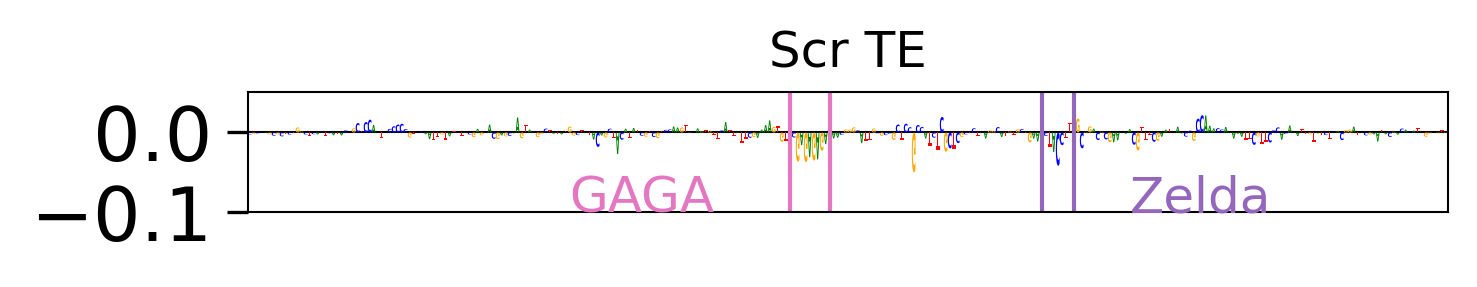

In [14]:
from tangermeme.ism import saturation_mutagenesis
from tangermeme.plot import plot_logo

resolution=200
num_merged=11
delta=2
ws=1
 
data_dir = '/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing'

X = seq_from_df(genome_fasta, locus_df, DNA_context_length)

SEQ_IDX = 100

flanking_context=200
start = 3150
end = 3450

scr_TE_attr = saturation_mutagenesis(model, X[SEQ_IDX].unsqueeze(0), device='cuda:0', start=start, end=end)[0]

fig, ax = init_subplots_exact(1,1,dpi=300, y_ratios=[0.1], x_ratios=[1], yspace=1.7)
logo = plot_logo(scr_TE_attr, ax=ax)
ax.grid(False)
ax.set_xticks([])
ax.set_xticklabels([])
# ax.set_xticks(np.arange(0, end-start+100, 100))
ax.tick_params(axis='both', which='both', length=5)  # Adjust tick length if needed
ax.axvline(135, color='#e377c2', lw=1)
ax.axvline(145, color='#e377c2', lw=1)
ax.axvline(198, color='#9467bd', lw=1)
ax.axvline(206, color='#9467bd', lw=1)
ax.text(80, -0.1, 'GAGA', color='#e377c2', fontsize=12)
ax.text(220, -0.1, 'Zelda', color='#9467bd', fontsize=12)
for spine in ax.spines.values():
    spine.set_visible(True)  
    spine.set_linewidth(0.5)  
    spine.set_edgecolor("black")  

plt.ylim([-0.1, 0.05])
plt.title('Scr TE', fontsize=12)
# fig.savefig("/scratch/gpfs/PRITYKIN/brendan/domino/figures/scr_te_attributions.pdf", format="pdf", dpi=300, bbox_inches='tight')
plt.show()

## Scr DTE

In [15]:
from domino.data.domino_data import process_bed_file_df

OFFSET=20000
boundary_length=200

ins_ws=1
ins_dir = "/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/insulations/insulation_files"
ins1_path = f"{ins_dir}/new_nc14_embryo_merged_all_11.resolution=200bp.insulation_{ins_ws}kb.bed"
ins_score1 = process_bed_file_df(ins1_path, target_col='ins_score')

chrom, start, end = "chr3R", 6893601, 6893800
# get insulation around boundary of interest
tmp = ins_score1.query('chrom == @chrom and start == @start and end==@end')
locus_df = ins_score1.iloc[tmp.index.item() - (OFFSET//boundary_length):tmp.index.item() + (OFFSET//boundary_length) + 1]
locus_df.reset_index(inplace=True, drop=True)

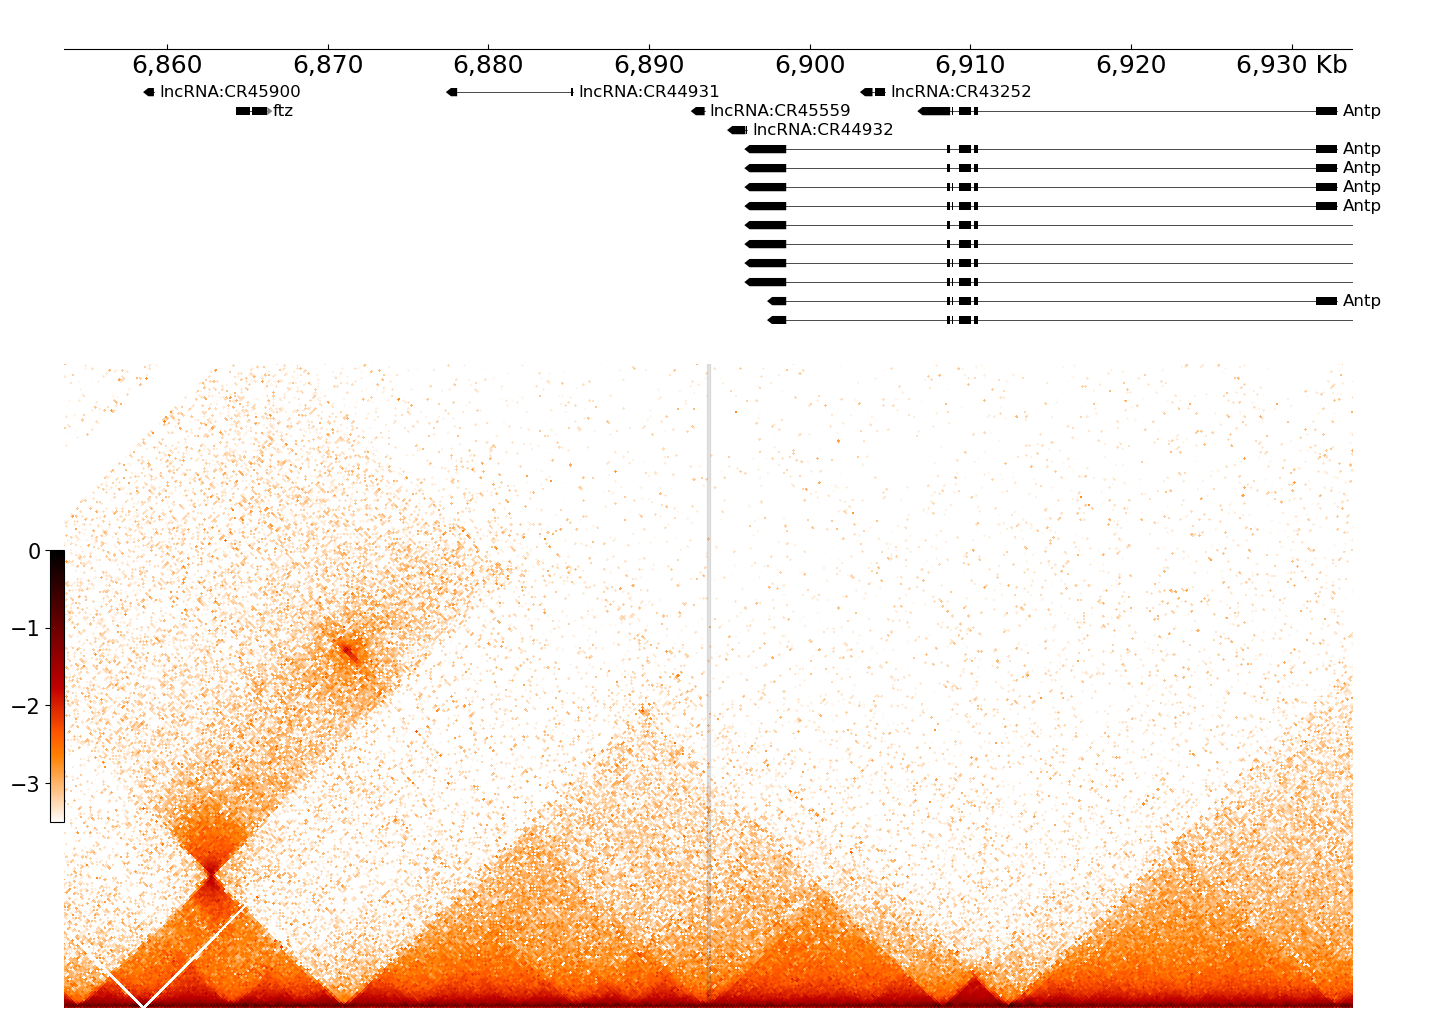

In [16]:
%matplotlib inline
# boundary = sf1.chrom, sf1.start, sf1.end
boundary = "chr3R", 6893601, 6893800
chrom, start, end = boundary

plt.rcParams.update(plt.rcParamsDefault)
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['font.size'] = 18

MCOOL_DATA_DIR='/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/mcools/'
ANNOT_DATA_DIR='/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/annotations/'
RESOLUTION=200
NUM_MERGED=11

HIC_KWARGS = dict(
    style='window', 
    resolution=200, 
    depth_ratio=1, 
    cmap='gist_heat_r', 
    norm='no', 
    transform='log10', 
    max_value=0, 
    min_value=-3.5, 
    grid=False,
)

frame = [
    coolbox.api.XAxis(fontsize=18, show_chrom=True),
    coolbox.api.BED(f"{ANNOT_DATA_DIR}/dm6.refGene.bed", gene_style='flybase', color='k', border_color=None),
    coolbox.api.Spacer(),
    coolbox.api.HiCMat(f"{MCOOL_DATA_DIR}/new_nc14_embryo_merged_all_11.mcool", **HIC_KWARGS),
    coolbox.core.coverage.HighLights(boundary, color='black', alpha=0.1),
    
]
from functools import reduce

frame = reduce(lambda x, y: x + y, frame)
fig = frame.plot(f"{chrom}:{start-40_000}-{end + 40_000}")
fig.set(facecolor="white")
# fig.savefig("/scratch/gpfs/PRITYKIN/brendan/domino/figures/strong_pred_locus.pdf", format="pdf")
display(fig)

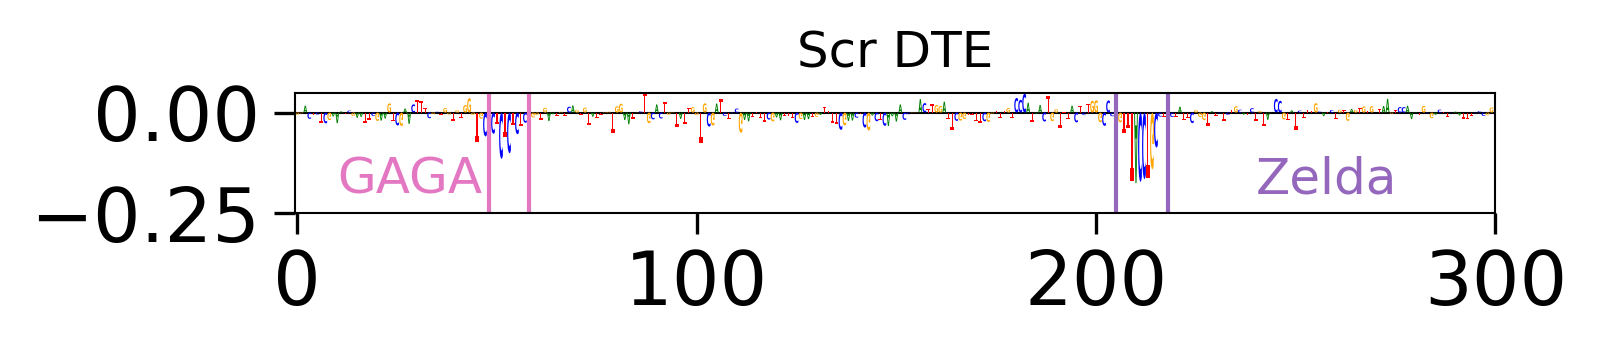

In [17]:
from tangermeme.ism import saturation_mutagenesis
from tangermeme.plot import plot_logo

resolution=200
num_merged=11
delta=2
ws=1
 
data_dir = '/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing'

X = seq_from_df(genome_fasta, locus_df, DNA_context_length)

SEQ_IDX = 100

flanking_context=200
start = 3100
end = 3400

scr_DTE_attr = saturation_mutagenesis(model, X[SEQ_IDX].unsqueeze(0), device='cuda:0', start=start, end=end)[0]

fig, ax = init_subplots_exact(1,1,dpi=300, y_ratios=[0.1], x_ratios=[1], yspace=1.7)
logo = plot_logo(scr_DTE_attr, ax=ax)
ax.grid(False)
# ax.set_xticks([])
# ax.set_xticklabels([])
ax.set_xticks(np.arange(0, end-start+100, 100))
ax.tick_params(axis='both', which='both', length=5)  # Adjust tick length if needed
ax.axvline(48, color='#e377c2', lw=1)
ax.axvline(58, color='#e377c2', lw=1)
ax.axvline(205, color='#9467bd', lw=1)
ax.axvline(218, color='#9467bd', lw=1)
ax.text(10, -0.2, 'GAGA', color='#e377c2', fontsize=12)
ax.text(240, -0.2, 'Zelda', color='#9467bd', fontsize=12)
for spine in ax.spines.values():
    spine.set_visible(True)  
    spine.set_linewidth(0.5)  
    spine.set_edgecolor("black")  

plt.ylim([-0.25, 0.05])
plt.title('Scr DTE', fontsize=12)
# fig.savefig("/scratch/gpfs/PRITYKIN/brendan/domino/figures/scr_te_attributions.pdf", format="pdf", dpi=300, bbox_inches='tight')
plt.show()

# Final plot

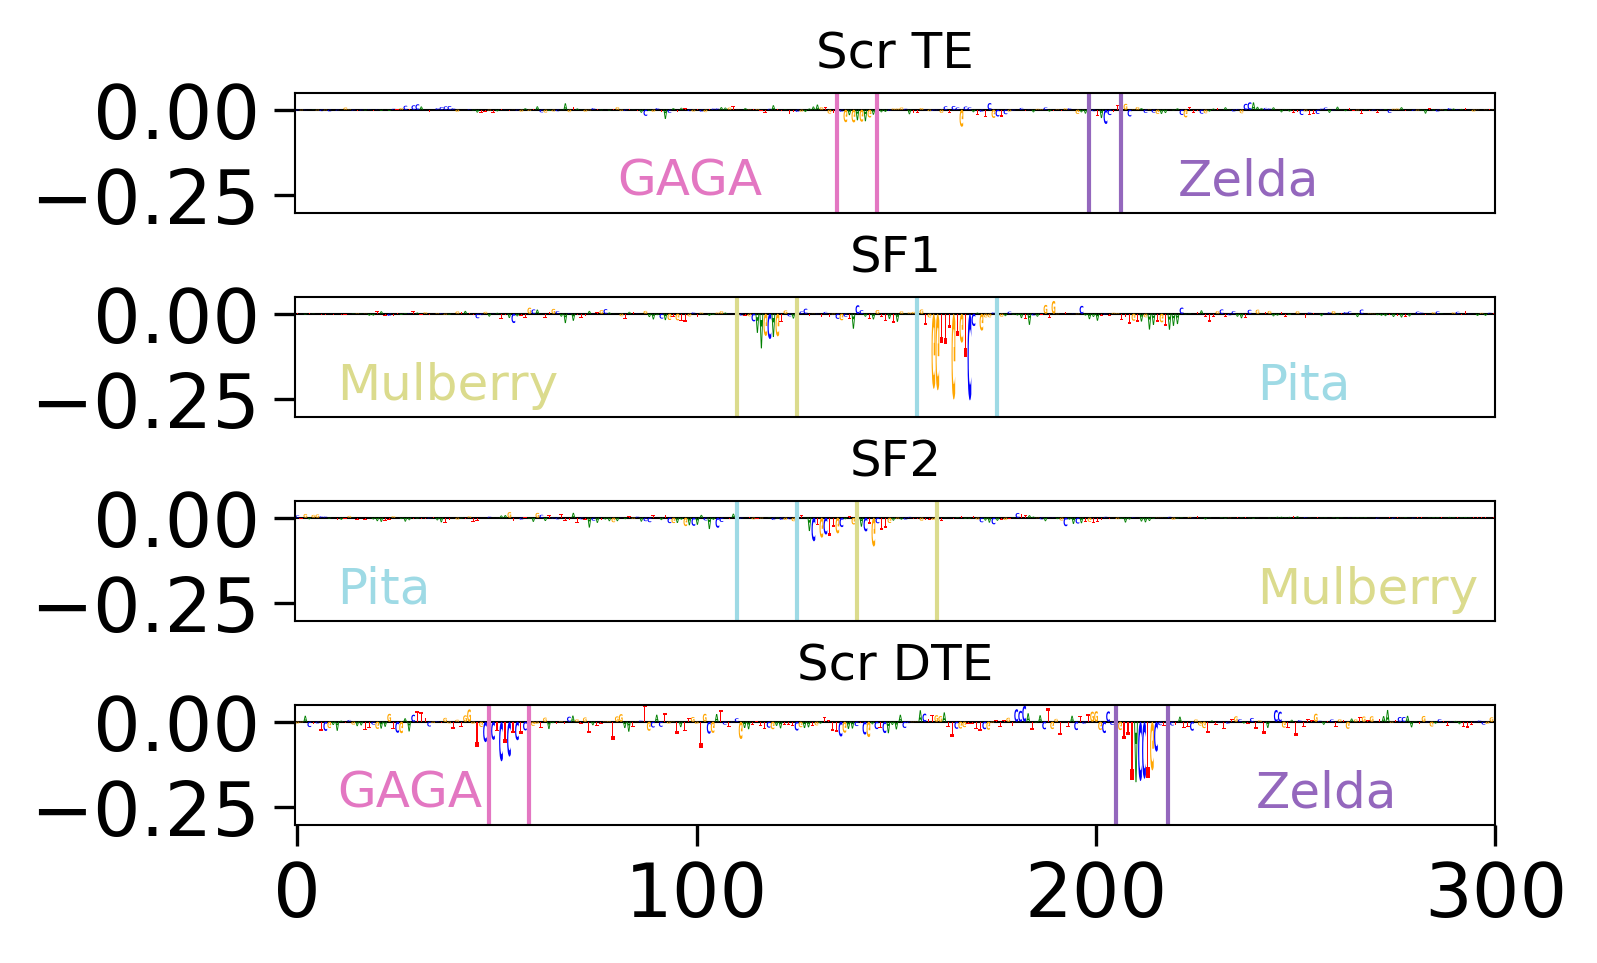

In [22]:

%matplotlib inline
fig, axs = init_subplots_exact(4,4,dpi=300, y_ratios=[0.1] * 4, x_ratios=[1], yspace=1.7)

ax = axs[0]
plt.sca(axs[0])
logo = plot_logo(scr_TE_attr, ax=ax)
ax.grid(False)
ax.set_xticks([])
ax.set_xticklabels([])
ax.tick_params(axis='both', which='both', length=5)  # Adjust tick length if needed
ax.axvline(135, color='#e377c2', lw=1)
ax.axvline(145, color='#e377c2', lw=1)
ax.axvline(198, color='#9467bd', lw=1)
ax.axvline(206, color='#9467bd', lw=1)
ax.text(80, -0.25, 'GAGA', color='#e377c2', fontsize=12)
ax.text(220, -0.25, 'Zelda', color='#9467bd', fontsize=12)
plt.ylim([-0.3, 0.05])
plt.title('Scr TE', fontsize=12)

ax = axs[1]
plt.sca(axs[1])
logo = plot_logo(sf1_attr, ax=ax)
ax.grid(False)
ax.set_xticks([])
ax.set_xticklabels([])
ax.tick_params(axis='both', which='both', length=5)  # Adjust tick length if needed
ax.axvline(110, color='#dbdb8d', lw=1)
ax.axvline(125, color='#dbdb8d', lw=1)
ax.axvline(155, color='#9edae5', lw=1)
ax.axvline(175, color='#9edae5', lw=1)
ax.text(10, -0.25, 'Mulberry', color='#dbdb8d', fontsize=12)
ax.text(240, -0.25, 'Pita', color='#9edae5', fontsize=12)
plt.ylim([-0.3, 0.05])
plt.title('SF1', fontsize=12)

ax = axs[2]
plt.sca(axs[2])
logo = plot_logo(sf2_attr, ax=ax)
ax.grid(False)
ax.set_xticks([])
ax.set_xticklabels([])
# ax.set_xticks(np.arange(0, end-start+100, 100))
ax.tick_params(axis='both', which='both', length=5)  # Adjust tick length if needed
ax.axvline(110, color='#9edae5', lw=1)
ax.axvline(125, color='#9edae5', lw=1)
ax.axvline(140, color='#dbdb8d', lw=1)
ax.axvline(160, color='#dbdb8d', lw=1)
ax.text(10, -0.25, 'Pita', color='#9edae5', fontsize=12)
ax.text(240, -0.25, 'Mulberry', color='#dbdb8d', fontsize=12)
plt.ylim([-0.3, 0.05])
plt.title('SF2', fontsize=12)

ax = axs[3]
plt.sca(axs[3])
logo = plot_logo(scr_DTE_attr, ax=ax)
ax.grid(False)
ax.set_xticks(np.arange(0, end-start+100, 100))
ax.tick_params(axis='both', which='both', length=5)  # Adjust tick length if needed
ax.axvline(48, color='#e377c2', lw=1)
ax.axvline(58, color='#e377c2', lw=1)
ax.axvline(205, color='#9467bd', lw=1)
ax.axvline(218, color='#9467bd', lw=1)
ax.text(10, -0.25, 'GAGA', color='#e377c2', fontsize=12)
ax.text(240, -0.25, 'Zelda', color='#9467bd', fontsize=12)
plt.ylim([-0.3, 0.05])
plt.title('Scr DTE', fontsize=12)

for ax in axs:
    for spine in ax.spines.values():
        spine.set_visible(True)  
        spine.set_linewidth(0.5)  
        spine.set_edgecolor("black") 

fig.savefig("/scratch/gpfs/PRITYKIN/brendan/domino/figures/scr_te_attributions.pdf", format="pdf", dpi=300, bbox_inches='tight')

plt.show()